In [1]:
!pip install kaggle


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import shutil

kaggle_dir = os.path.expanduser("~/.kaggle")
os.makedirs(kaggle_dir, exist_ok=True)

shutil.copy("kaggle.json", os.path.join(kaggle_dir, "kaggle.json"))

'C:\\Users\\Dell/.kaggle\\kaggle.json'

In [3]:
import os
import shutil

kaggle_dir = os.path.join(os.path.expanduser("~"), ".kaggle")
os.makedirs(kaggle_dir, exist_ok=True)

shutil.copy("kaggle.json", os.path.join(kaggle_dir, "kaggle.json"))

print("kaggle.json copied successfully!")

kaggle.json copied successfully!


In [4]:
!kaggle datasets download -d abdallahalidev/plantvillage-dataset

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
plantvillage-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [5]:
import zipfile
import os

zip_path = "plantvillage-dataset.zip"
extract_path = "./data/PlantVillage"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    for member in zip_ref.namelist():
        if member.startswith("plantvillage dataset/color/"):
            zip_ref.extract(member, extract_path)

print("Color dataset extracted successfully!")


Color dataset extracted successfully!


##Preprocessing

In [6]:
# 2️⃣ Import Libraries
from pathlib import Path
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt

# Project directory (current folder containing the notebook)
PROJECT_ROOT = Path.cwd()

# Dataset location
DATA_DIR = PROJECT_ROOT / "data" / "PlantVillage" / "plantvillage dataset" / "color"

# Model save location
MODEL_SAVE_PATH = PROJECT_ROOT / "smartfarm_cnn_best_model.keras"

print("Dataset Path:", DATA_DIR)
print("Dataset Exists:", DATA_DIR.exists())

print("Model Save Path:", MODEL_SAVE_PATH)


Dataset Path: F:\GAURAV\final year project\smartfarm cnn +ai v3\data\PlantVillage\plantvillage dataset\color
Dataset Exists: True
Model Save Path: F:\GAURAV\final year project\smartfarm cnn +ai v3\smartfarm_cnn_best_model.keras


In [7]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_gen = datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training"
)

val_gen = datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation"
)

print(f"✅ Classes found: {train_gen.num_classes}")

Found 43456 images belonging to 38 classes.
Found 10849 images belonging to 38 classes.
✅ Classes found: 38


In [8]:
# 5️⃣ CNN Model Definition

model = models.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(train_gen.num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 38)                  │           4,902 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,309,542 (12.62 MB)

 Trainable params: 3,309,542 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# 6️⃣ Model Training

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

# Save best model
model.save(MODEL_SAVE_PATH)
print(f"✅ Model saved to: {MODEL_SAVE_PATH}")


Epoch 1/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1601s 1s/step - accuracy: 0.5769 - loss: 1.4966 - val_accuracy: 0.7845 - val_loss: 0.7016
Epoch 2/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 957s 704ms/step - accuracy: 0.7756 - loss: 0.7141 - val_accuracy: 0.8597 - val_loss: 0.4524
Epoch 3/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1250s 902ms/step - accuracy: 0.8349 - loss: 0.5158 - val_accuracy: 0.9015 - val_loss: 0.3113
Epoch 4/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 909s 669ms/step - accuracy: 0.8736 - loss: 0.3863 - val_accuracy: 0.9195 - val_loss: 0.2571
Epoch 5/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1123s 827ms/step - accuracy: 0.8959 - loss: 0.3163 - val_accuracy: 0.9026 - val_loss: 0.2959
Epoch 6/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 914s 673ms/step - accuracy: 0.9116 - loss: 0.2652 - val_accuracy: 0.9145 - val_loss: 0.2761
Epoch 7/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 866s 638ms/step - accuracy: 0.9248 - loss: 0.2250 - val_accuracy: 0.9230 - val_loss: 0.2539
Epoch 8/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1070s 788ms/step - a

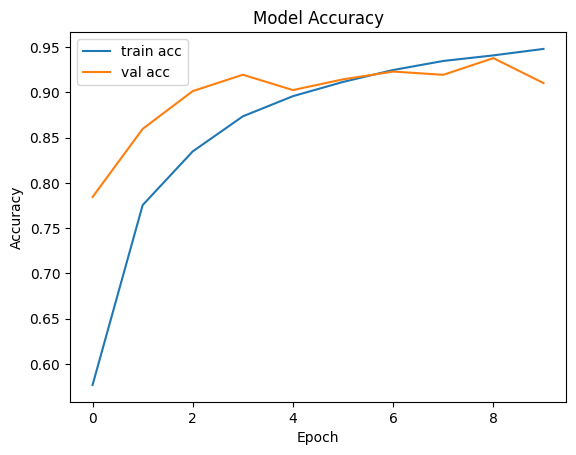

In [11]:
# 7️⃣ Training Visualization

plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [13]:
import json
from pathlib import Path

class_indices = train_gen.class_indices

save_path = Path.cwd() / "class_indices.json"

with open(save_path, "w") as f:
    json.dump(class_indices, f, indent=4)

print(f"✅ Class indices saved to: {save_path}")


✅ Class indices saved to: F:\GAURAV\final year project\smartfarm cnn +ai v3\class_indices.json


In [14]:
from pathlib import Path
from tensorflow.keras.models import load_model

# Path to the saved model
model_path = Path.cwd() / "smartfarm_cnn_best_model.keras"

# Load the model
model = load_model(model_path)

print("✅ Model loaded successfully!")
model.summary()


✅ Model loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 38)                  │           4,902 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,928,628 (37.87 MB)

 Trainable params: 3,309,542 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,619,086 (25.25 MB)

In [16]:
from pathlib import Path
import numpy as np
from tensorflow.keras.preprocessing import image

# Path to the image
img_path = (
    Path.cwd()
    / "data"
    / "PlantVillage"
    / "plantvillage dataset"
    / "color"
    / "Tomato___healthy"
    / "000146ff-92a4-4db6-90ad-8fce2ae4fddd___GH_HL Leaf 259.1.JPG"
)

# Load and preprocess the image
img = image.load_img(img_path, target_size=(128, 128))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Make prediction
pred = model.predict(img_array)
predicted_class = np.argmax(pred, axis=1)

print("Predicted class index:", predicted_class[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 318ms/step
Predicted class index: 37


In [18]:
from pathlib import Path
import os

# Path to the dataset folder
data_dir = Path.cwd() / "data" / "PlantVillage" / "plantvillage dataset" / "color"

# Get class names
class_names = sorted(
    [folder.name for folder in data_dir.iterdir() if folder.is_dir()]
)

print("Dataset path:", data_dir)
print("Total classes:", len(class_names))
print("First 5 classes:", class_names[:5])

Dataset path: F:\GAURAV\final year project\smartfarm cnn +ai v3\data\PlantVillage\plantvillage dataset\color
Total classes: 38
First 5 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [19]:
print("Predicted disease:", class_names[predicted_class[0]])

Predicted disease: Tomato___healthy


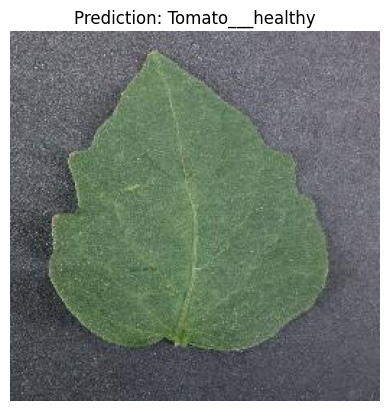

In [20]:
import matplotlib.pyplot as plt

plt.imshow(image.load_img(img_path))
plt.title(f"Prediction: {class_names[predicted_class[0]]}")
plt.axis("off")
plt.show()
